In [2]:
import sys
print(sys.executable)

/mnt/pixstor/data/lsxgf/miniconda/envs/py-scverse/bin/python


In [3]:

"""
XGBoost Binary Classifier for Gene Expression Data
Label: adata.obs['reactivity'] (0 or 1)
Input: h5ad files for train, val, test splits
"""

import numpy as np
import pandas as pd
import scanpy as sc
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    classification_report, confusion_matrix
)
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings("ignore")

In [8]:
"""
XGBoost Binary Classifier for Gene Expression Data
Label: adata.obs['reactivity'] (0 or 1)
Input: h5ad files for train, val, test splits
"""


# ── 1. Define gene lists ───────────────────────────────────────────────────────

# 20260903
from pathlib import Path

ensemble_mode = 'rankMin_study'
level = 'clonotype' # clonotype, cell

out_dir_root = Path("/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260814")
save_dir = out_dir_root / f'{ensemble_mode}_{level}'

gene_1_fiPath = save_dir / "GRN_gene_embedding_Chiffelle_genes_celltype_1.csv"
geneSet1 = pd.read_csv(gene_1_fiPath)
up_de_target_genes_ = geneSet1.iloc[:, 0].tolist()

gene_0_fiPath = save_dir / "GRN_gene_embedding_Chiffelle_genes_celltype_0.csv"
geneSet0 = pd.read_csv(gene_0_fiPath)
down_de_target_genes_ = geneSet0.iloc[:, 0].tolist()

In [9]:
ALL_GENES = up_de_target_genes_ + down_de_target_genes_

In [10]:
print(ALL_GENES)
print(len(ALL_GENES))

['GZMB', 'CCL4', 'CCL3', 'KLRD1', 'GNLY', 'CD83', 'KLRC1', 'ZNF683', 'TRDC', 'XCL2', 'GZMA', 'IFNG', 'GZMH', 'CCL4L2', 'FASLG', 'DUSP2', 'GADD45B', 'TNFRSF18', 'FGFBP2', 'HLA-DRA', 'TIGIT', 'RGS1', 'TNF', 'TRGV5', 'IRF4', 'TRDV1', 'LGALS1', 'HSPA1A', 'HMOX1', 'HSPA1B', 'STMN1', 'LEF1', 'SAT1', 'KLRG1', 'HSPB1', 'MYC', 'ANXA1', 'FOS', 'DUSP1', 'CD69', 'TIMP1', 'TUBA1B', 'TUBB', 'DNAJB1', 'FTL', 'MAL', 'CCR7']
47


In [4]:


# ── 2. Load data ───────────────────────────────────────────────────────────────
from pathlib import Path
data_dir = Path('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/processed_data/classifier/six_studies/test_lowery/hvg2000_by_study_6_89_genes/')
TRAIN_PATH = data_dir / "train_5_S_6Inter89_coarseLabel.h5ad"   # <-- update paths
VAL_PATH   = data_dir / "val_5_S_6Inter89_coarseLabel.h5ad"   # <-- update paths
TEST_PATH  = data_dir / "test_lowery_S_6Inter89_coarseLabel.h5ad"   # <-- update paths test_lowery_S_6Inter89

print("Loading h5ad files...")
adata_train = sc.read_h5ad(TRAIN_PATH)
adata_val   = sc.read_h5ad(VAL_PATH)
adata_test  = sc.read_h5ad(TEST_PATH)

# save xgboost 89 to a new dir:
out_dir = Path('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/XGBoost_lightModel_out/')
#out_dir = Path('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/XGBoost_lightModel_panel89_out/')

Loading h5ad files...


In [5]:
output_dir = out_dir

output_dir.mkdir(parents=True, exist_ok=True)

In [6]:
output_dir

PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/XGBoost_lightModel_out')

## tuning more parameters:



Extracting features...
  [train] shape=(89981, 47)  label 1: 10052  label 0: 79929
  [val] shape=(9998, 47)  label 1: 1117  label 0: 8881
  [test] shape=(7825, 47)  label 1: 437  label 0: 7388

Class balance → pos: 10052, neg: 79929, scale_pos_weight: 7.952

Training XGBoost...
[0]	validation_0-logloss:0.67812	validation_0-auc:0.81397	validation_1-logloss:0.67838	validation_1-auc:0.80145
[50]	validation_0-logloss:0.46996	validation_0-auc:0.87811	validation_1-logloss:0.47633	validation_1-auc:0.86545
[100]	validation_0-logloss:0.43346	validation_0-auc:0.89268	validation_1-logloss:0.44261	validation_1-auc:0.87783
[150]	validation_0-logloss:0.41750	validation_0-auc:0.89952	validation_1-logloss:0.42914	validation_1-auc:0.88253
[200]	validation_0-logloss:0.40892	validation_0-auc:0.90363	validation_1-logloss:0.42246	validation_1-auc:0.88452
[250]	validation_0-logloss:0.40151	validation_0-auc:0.90737	validation_1-logloss:0.41680	validation_1-auc:0.88649
[300]	validation_0-logloss:0.39489	vali

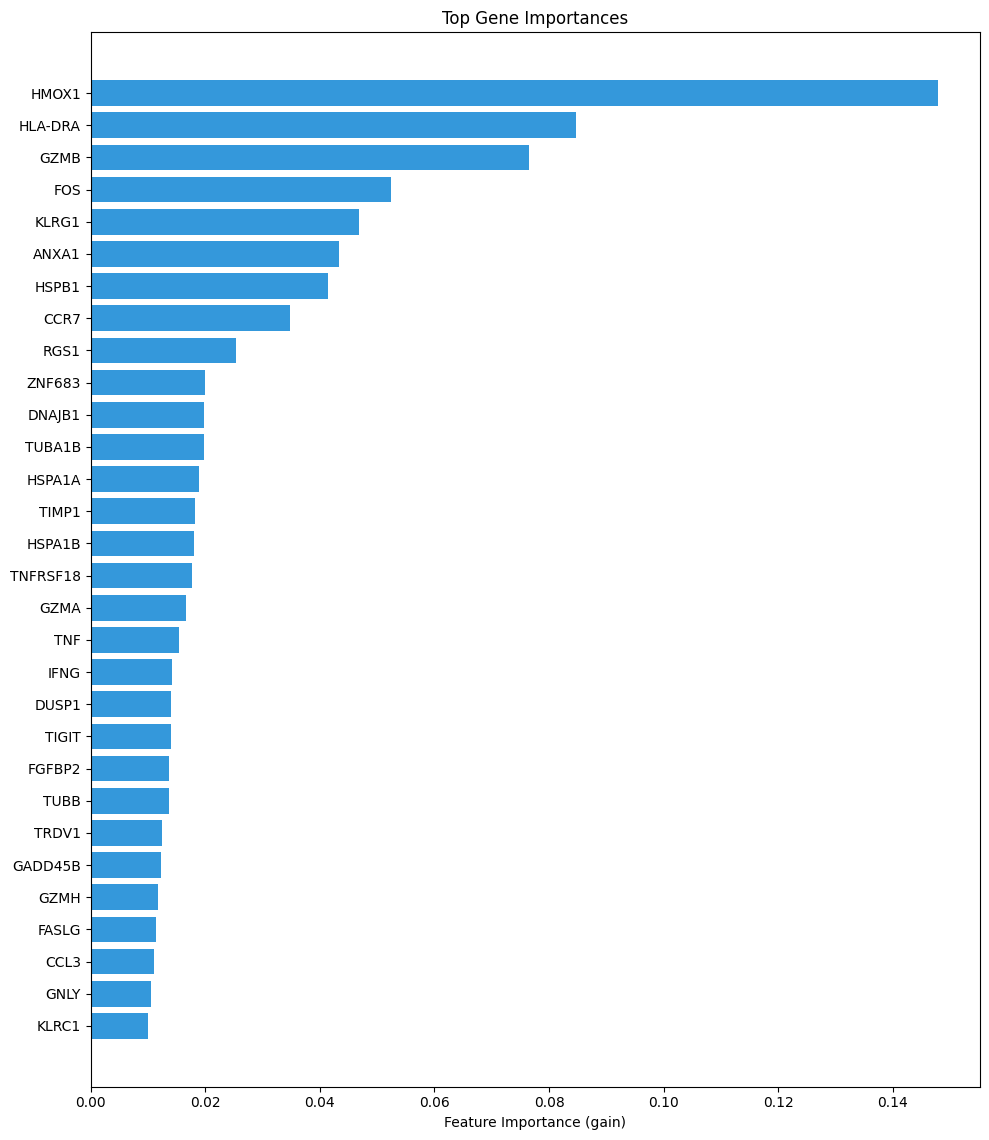

In [9]:
"""
XGBoost Binary Classifier for Gene Expression Data
Label: adata.obs['reactivity'] (0 or 1)
Input: h5ad files for train, val, test splits
Includes: custom metrics function + Optuna hyperparameter tuning
"""

import numpy as np
import pandas as pd
import scanpy as sc
import xgboost as xgb
import optuna
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score, precision_score,
    recall_score, balanced_accuracy_score, confusion_matrix,
    matthews_corrcoef
)
from sklearn.metrics.cluster import adjusted_rand_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)



# ── 3. Extract features (gene expression) and labels ──────────────────────────

def extract_features(adata, genes, split_name="split"):
    """Extract expression matrix for selected genes and binary labels."""
    # Filter to genes present in the dataset
    available = [g for g in genes if g in adata.var_names]
    missing   = set(genes) - set(available)
    if missing:
        print(f"  [{split_name}] Warning: {len(missing)} genes not found: {missing}")

    # Extract expression matrix (dense)
    X = adata[:, available].X
    if hasattr(X, "toarray"):          # handle sparse matrices
        X = X.toarray()
    X = pd.DataFrame(X, columns=available, index=adata.obs_names)
    X = X.reindex(columns=genes, fill_value=0)

    # Binary labels
    y = adata.obs["reactivity"].astype(int).values

    print(f"  [{split_name}] shape={X.shape}  "
          f"label 1: {y.sum()}  label 0: {(y==0).sum()}")
    return X, y

print("\nExtracting features...")
X_train, y_train = extract_features(adata_train, ALL_GENES, "train")
X_val,   y_val   = extract_features(adata_val,   ALL_GENES, "val")
X_test,  y_test  = extract_features(adata_test,  ALL_GENES, "test")

# ── 4. Handle class imbalance ──────────────────────────────────────────────────

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos   # compensates for imbalanced classes
print(f"\nClass balance → pos: {pos}, neg: {neg}, "
      f"scale_pos_weight: {scale_pos_weight:.3f}")

# ── 5. Build XGBoost classifier ────────────────────────────────────────────────

model = xgb.XGBClassifier(
    objective             = "binary:logistic",
    eval_metric           = ["logloss", "auc"],
    n_estimators          = 500,
    learning_rate         = 0.05,
    max_depth             = 4,
    min_child_weight      = 5,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    gamma                 = 1,
    reg_alpha             = 0.1,     # L1 regularisation
    reg_lambda            = 1.0,     # L2 regularisation
    scale_pos_weight      = scale_pos_weight,
    early_stopping_rounds = 30,      # moved here for XGBoost >= 1.6
    random_state          = 42,
    n_jobs                = -1,
)

# ── 6. Train with early stopping ───────────────────────────────────────────────

print("\nTraining XGBoost...")
model.fit(
    X_train, y_train,
    eval_set = [(X_train, y_train), (X_val, y_val)],
    verbose  = 50,
)

print(f"\nBest iteration: {model.best_iteration}")

# ── 7. Metrics function ────────────────────────────────────────────────────────

def output_metrics(output_file_path, predictions_list, function_names_list, test_labels):
    """
    Compute a comprehensive set of classification metrics.

    Parameters
    ----------
    output_file_path     : str or None — path to write CSV; pass None to skip writing
    predictions_list     : list of (pred_labels, pred_scores) tuples
    function_names_list  : list of str, one name per entry in predictions_list
    test_labels          : array-like of true binary labels

    Returns
    -------
    results : list of metric lists [precision, recall, f1, roc, acc, bal_acc, ari, mcc, gmean]
    """
    results = []
    for preds_score_tu in predictions_list:
        preds = preds_score_tu[0]
        score = preds_score_tu[1]
        precision         = precision_score(test_labels, preds, average='weighted')
        recall            = recall_score(test_labels, preds, average='weighted')
        f1                = f1_score(test_labels, preds, average='weighted')
        roc               = roc_auc_score(test_labels, score, average='weighted')
        accuracy          = accuracy_score(test_labels, preds)
        balanced_accuracy = balanced_accuracy_score(test_labels, preds)
        ari               = adjusted_rand_score(test_labels, preds)
        mcc               = matthews_corrcoef(test_labels, preds)
        tn, fp, fn, tp    = confusion_matrix(test_labels, preds).ravel()
        sen               = tp / (tp + fn)
        spe               = tn / (tn + fp)
        gmean             = (sen * spe) ** 0.5
        results.append([precision, recall, f1, roc, accuracy, balanced_accuracy, ari, mcc, gmean])

    metrics_names = ["Precision", "Recall", "F1", "ROC_AUC", "Accuracy",
                     "Balanced_accuracy", "ARI", "MCC", "Gmean"]

    if output_file_path is not None:
        with open(output_file_path, "w") as f:
            f.write("Classifying_Function," + ",".join(metrics_names) + "\n")
            for function_name, result in zip(function_names_list, results):
                f.write(f"{function_name}," + ",".join(map(str, result)) + "\n")

    # Pretty-print to console
    print(f"\n{'Metric':<22}" + "  ".join(f"{n:>14}" for n in function_names_list))
    for i, name in enumerate(metrics_names):
        vals = "  ".join(f"{r[i]:>14.4f}" for r in results)
        print(f"  {name:<20} {vals}")

    return results

def get_preds(mdl, X):
    return mdl.predict(X), mdl.predict_proba(X)[:, 1]

# ── 8. Evaluate default model ──────────────────────────────────────────────────

print("\n── Default model — Val & Test metrics ──")
output_metrics(
    None,
    [get_preds(model, X_val)],
    ["Val"],
    y_val,          # both splits evaluated against their own labels below
)
# Test set independently
print("\n── Default model — Test only ──")
output_metrics(None, [get_preds(model, X_test)], ["Test"], y_test)

model.save_model(output_dir / "xgboost_reactivity.json")
importance_df = pd.DataFrame({
    "gene"       : X_train.columns,
    "importance" : model.feature_importances_,
}).sort_values("importance", ascending=False)

importance_df.to_csv(output_dir / "gene_importance.csv", index=False)
joblib.dump(model, output_dir / "xgboost_reactivity.pkl")


importance_df["supports_label"] = '0'

# ── 9. Plot feature importance ─────────────────────────────────────────────────

top_n = min(30, len(importance_df))
top_df = importance_df.head(top_n)

colors = ["#e74c3c" if lbl == "1" else "#3498db"
          for lbl in top_df["supports_label"]]

fig, ax = plt.subplots(figsize=(10, top_n * 0.35 + 1))
ax.barh(top_df["gene"][::-1], top_df["importance"][::-1], color=colors[::-1])
ax.set_xlabel("Feature Importance (gain)")
ax.set_title("Top Gene Importances")

from matplotlib.patches import Patch
'''
ax.legend(handles=[
    Patch(color="#e74c3c", label="Supports label 1"),
    Patch(color="#3498db", label="Supports label 0"),
])
'''
plt.tight_layout()
plt.savefig(output_dir / "feature_importance.png", dpi=150)
print(f"\nSaved: {output_dir} / feature_importance.png")


### Reload the importance df and plot again:

In [10]:
import numpy as np
import pandas as pd
import scanpy as sc
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    classification_report, confusion_matrix
)
import matplotlib.pyplot as plt
import joblib
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")


Saved: /cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/XGBoost_lightModel_out / feature_importance.png


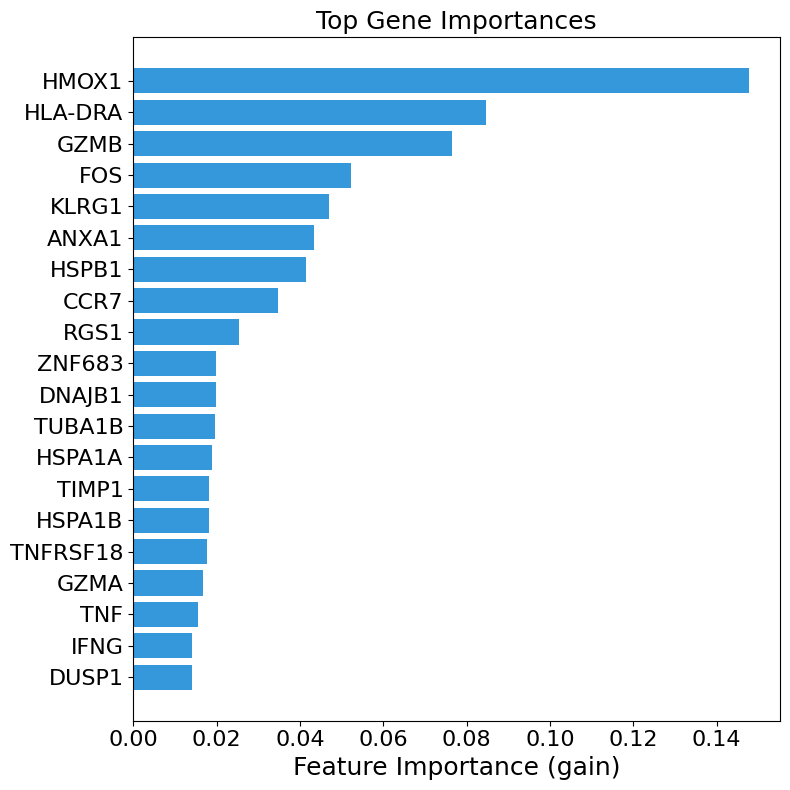

In [11]:



importance_df = pd.read_csv(output_dir / "gene_importance.csv", index_col=None)


importance_df["supports_label"] = '0'

# ── 9. Plot feature importance ─────────────────────────────────────────────────

top_n = min(20, len(importance_df))
top_df = importance_df.head(top_n)

colors = ["#e74c3c" if lbl == "1" else "#3498db"
          for lbl in top_df["supports_label"]]

fig, ax = plt.subplots(figsize=(8, top_n * 0.35 + 1))
ax.barh(top_df["gene"][::-1], top_df["importance"][::-1], color=colors[::-1])
ax.set_xlabel("Feature Importance (gain)", fontsize=18)
ax.set_title("Top Gene Importances", fontsize=18)
ax.tick_params(axis='y', rotation=0, labelsize=16)
ax.tick_params(axis='x', rotation=0, labelsize=16)

from matplotlib.patches import Patch
'''
ax.legend(handles=[
    Patch(color="#e74c3c", label="Supports label 1"),
    Patch(color="#3498db", label="Supports label 0"),
])
'''
plt.tight_layout()
plt.savefig(output_dir / "feature_importance.png", dpi=150)
print(f"\nSaved: {output_dir} / feature_importance.png")



In [12]:
def get_preds(mdl, X):
    return mdl.predict(X), mdl.predict_proba(X)[:, 1]

pred_y_test, score_y_test = get_preds(model, X_test)

pred_y_test.shape

type(y_test)

pivot = pd.DataFrame({
    "preds": pred_y_test,
    "score": score_y_test,
    "true_reactivity": y_test.astype('str')
})

pivot_sorted = pivot.sort_values("score", ascending=False).reset_index(drop=True)

topk_list = list(range(25,525, 25))

results = []

for k in topk_list:
    subset = pivot_sorted.iloc[:k]

    # number of true positives
    tp = (subset["true_reactivity"] == "1").sum()
    #print(tp)

    precision = tp / k

    results.append({
        "top_n": k,
        #"true_positive": tp,
        "XGBoost_classifier": precision
    })

precision_df = pd.DataFrame(results)
print(precision_df)

    top_n  XGBoost_classifier
0      25            0.800000
1      50            0.800000
2      75            0.720000
3     100            0.700000
4     125            0.656000
5     150            0.633333
6     175            0.617143
7     200            0.585000
8     225            0.560000
9     250            0.552000
10    275            0.545455
11    300            0.550000
12    325            0.529231
13    350            0.517143
14    375            0.512000
15    400            0.497500
16    425            0.491765
17    450            0.480000
18    475            0.471579
19    500            0.464000


In [13]:
print(precision_df)

    top_n  XGBoost_classifier
0      25            0.800000
1      50            0.800000
2      75            0.720000
3     100            0.700000
4     125            0.656000
5     150            0.633333
6     175            0.617143
7     200            0.585000
8     225            0.560000
9     250            0.552000
10    275            0.545455
11    300            0.550000
12    325            0.529231
13    350            0.517143
14    375            0.512000
15    400            0.497500
16    425            0.491765
17    450            0.480000
18    475            0.471579
19    500            0.464000


In [14]:
precision_df.to_csv(output_dir / 'test_lowery_model_topn_precision.csv')  

In [15]:

output_metrics(output_file_path=output_dir / 'test_lowery_XGBoost_model_prediction_scores.csv',  
               predictions_list = [(pred_y_test, score_y_test)], function_names_list = ['XGBoost_model'], test_labels=y_test)


Metric                 XGBoost_model
  Precision                    0.9430
  Recall                       0.8814
  F1                           0.9046
  ROC_AUC                      0.8927
  Accuracy                     0.8814
  Balanced_accuracy            0.8080
  ARI                          0.3025
  MCC                          0.4032
  Gmean                        0.8038


[[0.9429794889238579,
  0.8814057507987221,
  0.9046279907073316,
  0.8927334696997666,
  0.8814057507987221,
  0.8080169586651123,
  0.3024913390758292,
  0.4031764191586398,
  0.8037822586080545]]


Running Optuna tuning (50 trials) — optimising val ROC-AUC ...


Best trial: 47. Best value: 0.896187: 100%|█████| 50/50 [31:53<00:00, 38.27s/it]



Best val ROC-AUC : 0.8962
Best params:
  n_estimators: 794
  learning_rate: 0.02487924046117278
  max_depth: 8
  min_child_weight: 17
  gamma: 0.016844537356273087
  subsample: 0.7653619094819931
  colsample_bytree: 0.902110402022107
  colsample_bylevel: 0.7118658694888653
  reg_alpha: 0.13401178609648484
  reg_lambda: 0.020544442222812483

── Tuned model — Val ──

Metric                   Val (tuned)
  Precision                    0.9031
  Recall                       0.8408
  F1                           0.8616
  ROC_AUC                      0.8962
  Accuracy                     0.8408
  Balanced_accuracy            0.8110
  ARI                          0.3397
  MCC                          0.4729
  Gmean                        0.8101

── Tuned model — Test metrics ──

Metric                  Test (tuned)
  Precision                    0.9438
  Recall                       0.8888
  F1                           0.9096
  ROC_AUC                      0.8993
  Accuracy                  

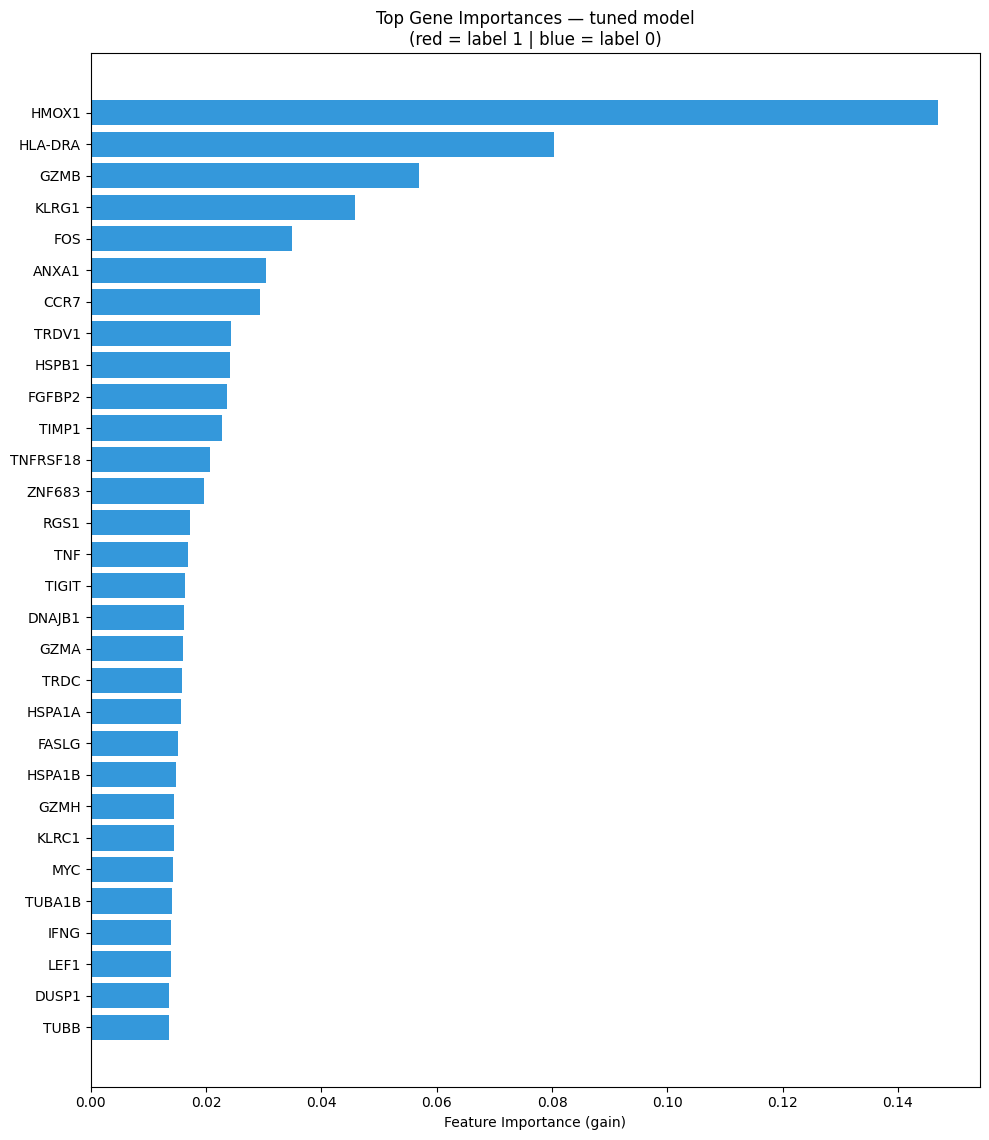

In [16]:

# ── 9. Optuna hyperparameter tuning ───────────────────────────────────────────
#
#  Parameters searched and why they matter for gene-expression data:
#
#  max_depth          — tree depth; shallower = less overfit on small cohorts
#  min_child_weight   — min samples per leaf; higher = more regularisation
#  gamma              — min loss reduction to split; higher = more conservative
#  subsample          — row sampling per tree; reduces variance
#  colsample_bytree   — gene (feature) sampling per tree; reduces correlation
#  colsample_bylevel  — gene sampling per tree level; finer-grained dropout
#  reg_alpha          — L1 penalty; encourages sparse gene selection
#  reg_lambda         — L2 penalty; shrinks weights
#  learning_rate      — step size; lower = more robust, needs more trees
#  n_estimators       — number of trees; tuned jointly with learning_rate
#
#  Objective: maximise ROC-AUC on the validation set.

N_TRIALS = 50   # raise to 100-200 for a more thorough search

def objective(trial):
    params = dict(
        objective             = "binary:logistic",
        eval_metric           = "auc",
        n_estimators          = trial.suggest_int("n_estimators", 100, 800),
        learning_rate         = trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        max_depth             = trial.suggest_int("max_depth", 2, 8),
        min_child_weight      = trial.suggest_int("min_child_weight", 1, 20),
        gamma                 = trial.suggest_float("gamma", 0.0, 5.0),
        subsample             = trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree      = trial.suggest_float("colsample_bytree", 0.3, 1.0),
        colsample_bylevel     = trial.suggest_float("colsample_bylevel", 0.3, 1.0),
        reg_alpha             = trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        reg_lambda            = trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        scale_pos_weight      = scale_pos_weight,
        early_stopping_rounds = 30,
        random_state          = 42,
        n_jobs                = -1,
    )
    clf = xgb.XGBClassifier(**params)
    clf.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    probs = clf.predict_proba(X_val)[:, 1]
    return roc_auc_score(y_val, probs, average='weighted')

print(f"\nRunning Optuna tuning ({N_TRIALS} trials) — optimising val ROC-AUC ...")
study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

print(f"\nBest val ROC-AUC : {study.best_value:.4f}")
print(f"Best params:\n" + "\n".join(f"  {k}: {v}" for k, v in study.best_params.items()))

# ── 10. Retrain with best params ───────────────────────────────────────────────

best_model = xgb.XGBClassifier(
    objective             = "binary:logistic",
    eval_metric           = ["logloss", "auc"],
    **study.best_params,
    scale_pos_weight      = scale_pos_weight,
    early_stopping_rounds = 30,
    random_state          = 42,
    n_jobs                = -1,
)
best_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

print("\n── Tuned model — Val ──")
output_metrics(
    None,
    [get_preds(best_model, X_val)],
    ["Val (tuned)"],
    y_val,          # both splits evaluated against their own labels below
)

print("\n── Tuned model — Test metrics ──")
output_metrics(None, [get_preds(best_model, X_test)], ["Test (tuned)"], y_test)

# ── 11. Feature importance (tuned model) ──────────────────────────────────────

importance_df = pd.DataFrame({
    "gene"       : X_train.columns,
    "importance" : best_model.feature_importances_,
}).sort_values("importance", ascending=False)
importance_df["supports_label"] = "0"

print("\nTop 20 most important genes:")
print(importance_df.head(20).to_string(index=False))

top_n  = min(30, len(importance_df))
top_df = importance_df.head(top_n)
colors = ["#e74c3c" if lbl == "1" else "#3498db" for lbl in top_df["supports_label"]]

fig, ax = plt.subplots(figsize=(10, top_n * 0.35 + 1))
ax.barh(top_df["gene"][::-1], top_df["importance"][::-1], color=colors[::-1])
ax.set_xlabel("Feature Importance (gain)")
ax.set_title("Top Gene Importances — tuned model\n(red = label 1 | blue = label 0)")
from matplotlib.patches import Patch
"""
ax.legend(handles=[Patch(color="#e74c3c", label="Supports label 1"),
                   Patch(color="#3498db", label="Supports label 0")])
"""
plt.tight_layout()
plt.savefig(output_dir / "best_model_feature_importance.png", dpi=150)
print("\nSaved: best_model_feature_importance.png")
print("\nDone ✓")

In [17]:
# ── 10. Save model and importance table ────────────────────────────────────────
import joblib

best_model.save_model(output_dir / "best_model_xgboost_reactivity.json")
importance_df.to_csv(output_dir / "best_model_gene_importance.csv", index=False)
joblib.dump(best_model, output_dir / "best_model_xgboost_reactivity.pkl")

print(f"\nSaved: {output_dir} xgboost_reactivity.json / .pkl, gene_importance.csv")
print("\nDone ✓")


Saved: /cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/XGBoost_lightModel_out xgboost_reactivity.json / .pkl, gene_importance.csv

Done ✓


In [20]:
importance_df = pd.read_csv(output_dir / "best_model_gene_importance.csv")

In [21]:
importance_df.head(40)

,gene,importance,supports_label
0,HMOX1,0.146882,0
1,HLA-DRA,0.080273,0
2,GZMB,0.057010,0
3,KLRG1,0.045812,0
4,FOS,0.034953,0
5,ANXA1,0.030383,0
6,CCR7,0.029312,0
7,TRDV1,0.024249,0
8,HSPB1,0.024178,0
9,FGFBP2,0.023568,0


In [11]:
# load the model back:
import joblib
"""
XGBoost Binary Classifier for Gene Expression Data
Label: adata.obs['reactivity'] (0 or 1)
Input: h5ad files for train, val, test splits
Includes: custom metrics function + Optuna hyperparameter tuning
"""

import numpy as np
import pandas as pd
import scanpy as sc
import xgboost as xgb
import optuna
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score, precision_score,
    recall_score, balanced_accuracy_score, confusion_matrix,
    matthews_corrcoef
)
from sklearn.metrics.cluster import adjusted_rand_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)



# ── 3. Extract features (gene expression) and labels ──────────────────────────

def extract_features(adata, genes, split_name="split"):
    """Extract expression matrix for selected genes and binary labels."""
    # Filter to genes present in the dataset
    available = [g for g in genes if g in adata.var_names]
    missing   = set(genes) - set(available)
    if missing:
        print(f"  [{split_name}] Warning: {len(missing)} genes not found: {missing}")

    # Extract expression matrix (dense)
    X = adata[:, available].X
    if hasattr(X, "toarray"):          # handle sparse matrices
        X = X.toarray()
    X = pd.DataFrame(X, columns=available, index=adata.obs_names)
    X = X.reindex(columns=genes, fill_value=0)

    # Binary labels
    y = adata.obs["reactivity"].astype(int).values

    print(f"  [{split_name}] shape={X.shape}  "
          f"label 1: {y.sum()}  label 0: {(y==0).sum()}")
    return X, y

print("\nExtracting features...")
X_train, y_train = extract_features(adata_train, ALL_GENES, "train")
X_val,   y_val   = extract_features(adata_val,   ALL_GENES, "val")
X_test,  y_test  = extract_features(adata_test,  ALL_GENES, "test")





Extracting features...
  [train] shape=(89981, 47)  label 1: 10052  label 0: 79929
  [val] shape=(9998, 47)  label 1: 1117  label 0: 8881
  [test] shape=(7825, 47)  label 1: 437  label 0: 7388


In [13]:
best_model = joblib.load(output_dir / "best_model_xgboost_reactivity.pkl")

In [14]:
best_model.feature_importances_.max()

0.14688158

In [15]:
'TRGV5' in X_test.columns

True

In [16]:
len(ALL_GENES)

47

In [17]:
def get_preds(mdl, X):
    return mdl.predict(X), mdl.predict_proba(X)[:, 1]

pred_y_test, score_y_test = get_preds(best_model, X_test)

pred_y_test.shape

type(y_test)

pivot = pd.DataFrame({
    "preds": pred_y_test,
    "score": score_y_test,
    "true_reactivity": y_test.astype('str')
})

pivot_sorted = pivot.sort_values("score", ascending=False).reset_index(drop=True)

topk_list = list(range(25,525, 25))

results = []

for k in topk_list:
    subset = pivot_sorted.iloc[:k]

    # number of true positives
    tp = (subset["true_reactivity"] == "1").sum()
    #print(tp)

    precision = tp / k

    results.append({
        "top_n": k,
        #"true_positive": tp,
        "XGBoost_classifier": precision
    })

precision_df = pd.DataFrame(results)
print(precision_df)

    top_n  XGBoost_classifier
0      25            0.800000
1      50            0.760000
2      75            0.706667
3     100            0.690000
4     125            0.696000
5     150            0.673333
6     175            0.640000
7     200            0.620000
8     225            0.600000
9     250            0.580000
10    275            0.556364
11    300            0.533333
12    325            0.532308
13    350            0.520000
14    375            0.514667
15    400            0.512500
16    425            0.508235
17    450            0.486667
18    475            0.467368
19    500            0.464000


In [18]:
precision_df.to_csv(output_dir / 'test_lowery_best_model_topn_precision.csv')

In [21]:
output_metrics(output_file_path=output_dir / 'test_lowery_XGBoost_best_model_prediction_scores.csv',    
               predictions_list = [(pred_y_test, score_y_test)], function_names_list = ['XGBoost_best_model'], test_labels=y_test)


Metric                XGBoost_best_model
  Precision                    0.9438
  Recall                       0.8888
  F1                           0.9096
  ROC_AUC                      0.8993
  Accuracy                     0.8888
  Balanced_accuracy            0.8109
  ARI                          0.3208
  MCC                          0.4164
  Gmean                        0.8061


[[0.9438240282891874,
  0.888817891373802,
  0.9095934518152041,
  0.8993385897596324,
  0.888817891373802,
  0.8108657554646721,
  0.32084102572341106,
  0.4163503068627248,
  0.806103327296066]]

In [22]:
output_dir

PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/XGBoost_lightModel_out')

## conclusion: the Optuna tuned model is better. 


Saved: /cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/XGBoost_lightModel_out / best_model_feature_importance.png


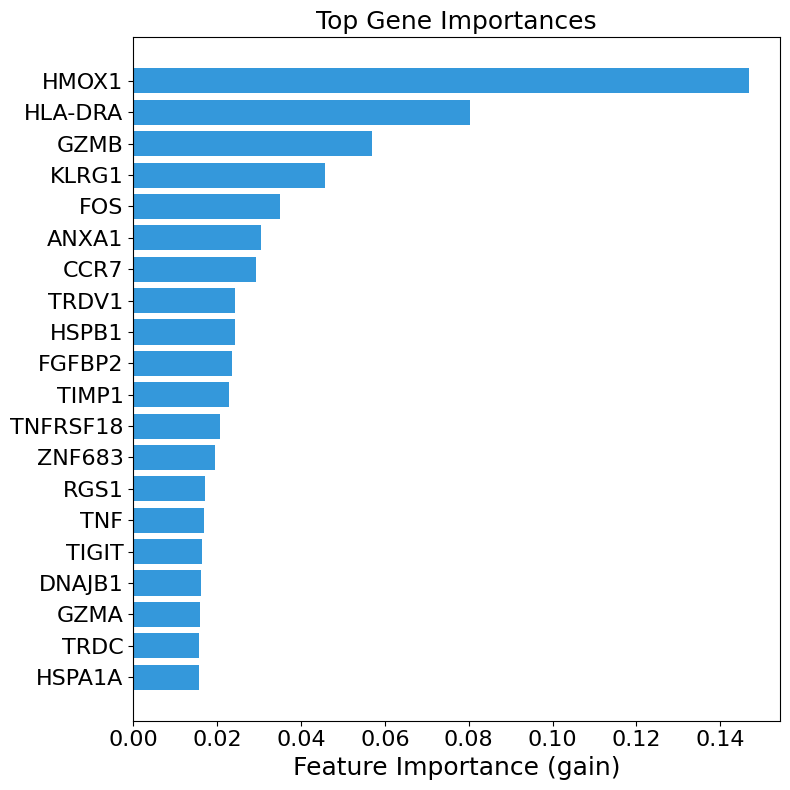

In [23]:



importance_df = pd.read_csv(output_dir / "best_model_gene_importance.csv", index_col=None)


#importance_df["supports_label"] = '0'

# ── 9. Plot feature importance ─────────────────────────────────────────────────

top_n = min(20, len(importance_df))
top_df = importance_df.head(top_n)

colors = ["#e74c3c" if lbl == "1" else "#3498db"
          for lbl in top_df["supports_label"]]

fig, ax = plt.subplots(figsize=(8, top_n * 0.35 + 1))
ax.barh(top_df["gene"][::-1], top_df["importance"][::-1], color=colors[::-1])
ax.set_xlabel("Feature Importance (gain)", fontsize=18)
ax.set_title("Top Gene Importances", fontsize=18)
ax.tick_params(axis='y', rotation=0, labelsize=16)
ax.tick_params(axis='x', rotation=0, labelsize=16)

from matplotlib.patches import Patch
'''
ax.legend(handles=[
    Patch(color="#e74c3c", label="Supports label 1"),
    Patch(color="#3498db", label="Supports label 0"),
])
'''
plt.tight_layout()
plt.savefig(output_dir / "best_model_feature_importance.png", dpi=150)
print(f"\nSaved: {output_dir} / best_model_feature_importance.png")

In [24]:
# save the 47 genes to local so later can run:
len(ALL_GENES)

47

In [37]:
df = pd.DataFrame({'gene': ALL_GENES})
df.to_csv('./scTRP_47_gene_list.csv', index=False)

In [38]:
df_check = pd.read_csv('./scTRP_47_gene_list.csv')
genes_check = df_check.iloc[:, 0].tolist()
assert genes_check == ALL_GENES